<a href="https://colab.research.google.com/github/juleuzun/Python_DataScience_Bootcamp/blob/main/Lessons/Lesson_09_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Libraries

In [3]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, ReLU, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
import matplotlib.pyplot as plt


# Data

In [4]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [5]:
X_train.shape

(60000, 28, 28)

In [6]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

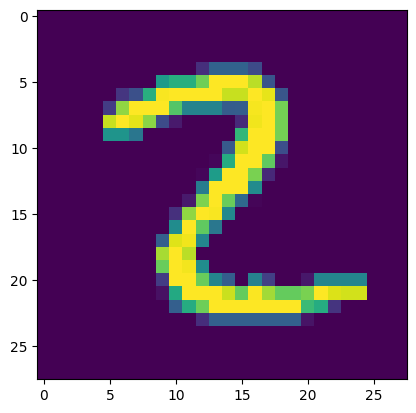

In [7]:
plt.imshow(X_train[76])

# Model

In [8]:
cnn_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3)),
    ReLU(),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3)),
    ReLU(),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
cnn_model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

# Training

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [13]:
cnn_model.fit(X_train,y_train, epochs=20,batch_size=64,validation_data=(X_test, y_test))
cnn_model.save('/content/drive/MyDrive/TechIstanbul/Lesson_09_cnn.keras')

Epoch 1/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 60s 64ms/step - accuracy: 0.9956 - loss: 0.0139 - val_accuracy: 0.9818 - val_loss: 0.0870
Epoch 2/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 64ms/step - accuracy: 0.9955 - loss: 0.0160 - val_accuracy: 0.9853 - val_loss: 0.0902
Epoch 3/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 60s 64ms/step - accuracy: 0.9963 - loss: 0.0140 - val_accuracy: 0.9868 - val_loss: 0.0705
Epoch 4/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 59s 63ms/step - accuracy: 0.9959 - loss: 0.0143 - val_accuracy: 0.9837 - val_loss: 0.0808
Epoch 5/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 60s 64ms/step - accuracy: 0.9968 - loss: 0.0116 - val_accuracy: 0.9854 - val_loss: 0.0768
Epoch 6/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 62ms/step - accuracy: 0.9963 - loss: 0.0126 - val_accuracy: 0.9865 - val_loss: 0.0806
Epoch 7/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 84s 64ms/step - accuracy: 0.9959 - loss: 0.0138 - val_accuracy: 0.9861 - val_loss: 0.0872
Epoch 8/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 60s 63ms/step - accuracy: 0.9970 - loss: 0.0125 - 

# Filter Visualization

In [14]:
layer_index = 5
layer = cnn_model.layers[layer_index]

In [15]:
filters, biases = layer.get_weights()

In [16]:
n_filters = filters.shape[3]

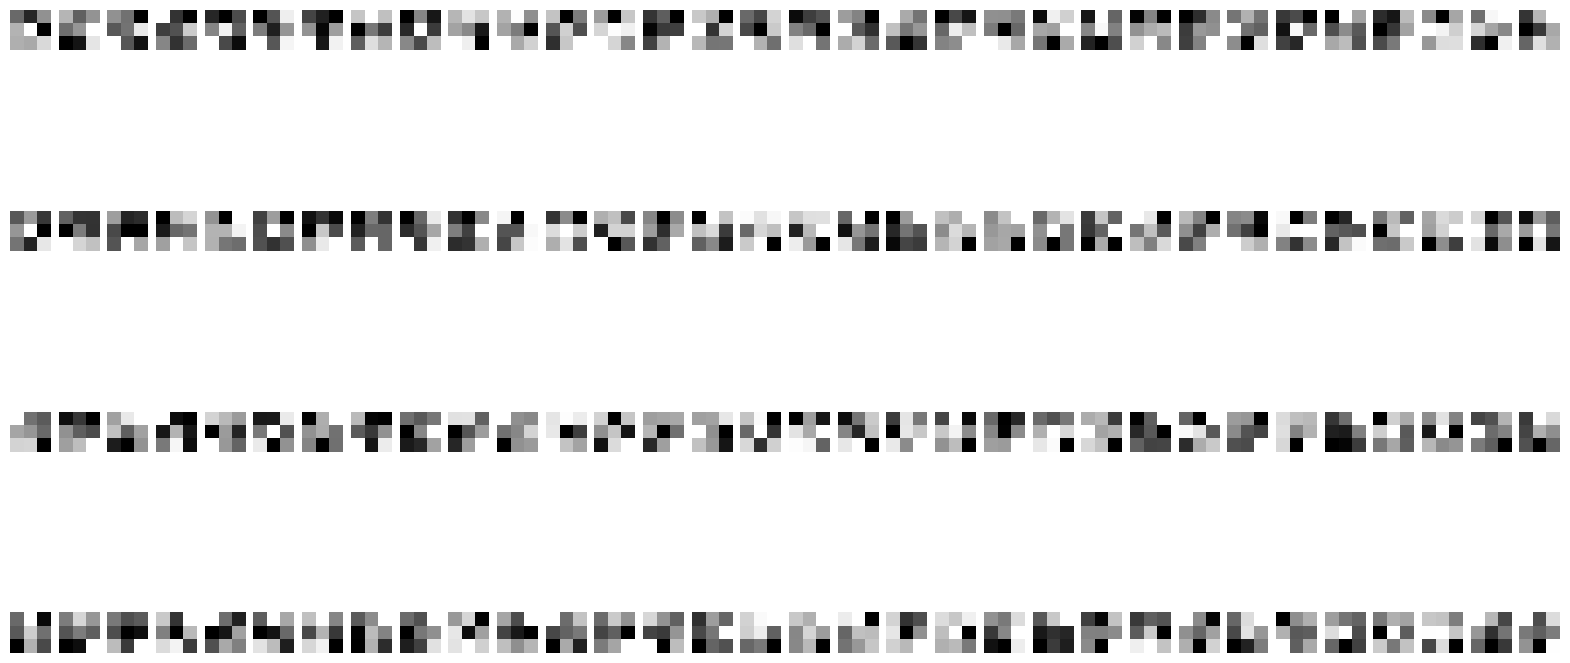

In [17]:
plt.figure(figsize=(20,10))

for i in range(n_filters):
  f = filters[:,:,:,i]
  plt.subplot(4,32,i+1)
  plt.imshow(f[:,:,0],cmap='gray')
  plt.axis('off')
plt.show()

# Real-Time Testing

In [18]:
from PIL import Image
import numpy as np

In [19]:
def predict(image_path):
  img = Image.open(image_path).convert('L')
  img = img.resize((28,28))
  img_array = np.array(img)

  img_array = img_array.reshape(-1,28,28,1)/255

  prediction = cnn_model.predict(img_array)

  predicted_number = np.argmax(prediction)

  print(predicted_number)

  plt.imshow(img,cmap='gray')
  plt.title(f"Prediction : {predicted_number}")
  plt.axis('off')
  plt.show()

Enter the file path of the image you want to predict: /content/drive/MyDrive/TechIstanbul/6.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1


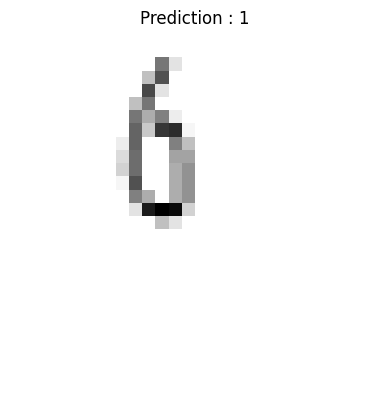

In [24]:
user_input = input("Enter the file path of the image you want to predict: ")
predict(user_input)

In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
